In [44]:
import gc
import tempfile
import os.path
import pickle as pkl
import numpy as np
import random
from tqdm import tqdm
import json
import torch
import numpy as np
from sklearn import metrics
from sklearn.metrics import make_scorer
from sklearn.model_selection import KFold, cross_validate
from functools import partial
from utils import get_texts_for_ptype
from sklearn.model_selection import RepeatedKFold

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from filelock import FileLock
from torch.utils.data import random_split
from typing import Dict
from scipy.optimize import minimize_scalar

import torch_geometric.transforms as T
from torch_geometric.data import Data
from torch_geometric.nn import GATConv, SAGEConv, GCNConv
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.nn.aggr import PowerMeanAggregation, SoftmaxAggregation, SetTransformerAggregation, MLPAggregation, LSTMAggregation, SortAggregation, EquilibriumAggregation
from sklearn.utils.multiclass import unique_labels
from sklearn.feature_extraction.text import HashingVectorizer, TfidfVectorizer

from ray import train, tune

import datasets
from datasets import load_dataset, Dataset, load_metric

In [1]:
ptype2model = {
    'is_rct': 'BioBERT',
    'is_sr': 'PubMedBERT',
    'is_casecontrol': 'PubMedBERT',
    'is_cohort': 'PubMedBERT',
    'is_guideline': 'DistilBERT'
}

In [24]:
neg_pos_ratio_dict = {
    "is_rct": 5585042/489295,
    "is_sr": 5659292/121063,
    "is_casecontrol": 5628219/65790,
    "is_cohort": 5632460/78688,
    "is_guideline": 5676411/33826
}

def calc_precision(recall, specificity, neg_pos_ratio):
    return recall / (recall + neg_pos_ratio * (1 - specificity) + 1e-15)

def calc_f1(recall, precision):
    return 2*recall*precision/(recall+precision + 1e-15)

In [40]:
def predict(df, db=0):
    return [int(x>=db) for x in df ]

def get_scores(predictions):
    return [np.exp(p[1])/(np.exp(p[0]) + np.exp(p[1])) for p in predictions]

In [28]:
def load_data(data_dir="../data", ptype="is_rct"):
    model_name = ptype2model[ptype]
    x_tensor_path = os.path.join(data_dir, f"x_tensor_{model_name}_sample.pkl")
    with open(x_tensor_path, "rb") as f:
        x_tensor = pkl.load(f)
    
    pmid2node_id_path = os.path.join(data_dir, "pmid2node_id_sample.json")
    with open(pmid2node_id_path, "r") as f:
        pmid2node_id = json.load(f)
    
    PMIDS = os.path.join(data_dir, "pmids.pkl") 
    with open(PMIDS, 'rb') as f:
        pmids = pkl.load(f)
    
    edge_index_path = os.path.join(data_dir, "edge_index_sample.pkl")
    with open(edge_index_path, "rb") as f:
        edge_index = pkl.load(f)
    
    num_nodes = len(pmid2node_id)
    train_mask = [False for _ in range(num_nodes)]
    val_mask = [False for _ in range(num_nodes)]
    test_mask = [False for _ in range(num_nodes)]
        
    train_pmids = pmids[ptype]['pos']['train'] + pmids[ptype]['neg']['train']
    val_pmids = pmids[ptype]['pos']['val'] + pmids[ptype]['neg']['val']
    test_pmids = pmids[ptype]['pos']['test'] + pmids[ptype]['neg']['test']
        
    for pmid in train_pmids:
        if str(pmid) in pmid2node_id:
            node_id = pmid2node_id[str(pmid)]
            train_mask[node_id] = True
        
    for pmid in val_pmids:
        if str(pmid) in pmid2node_id:
            node_id = pmid2node_id[str(pmid)]
            val_mask[node_id] = True
                
    for pmid in test_pmids:
        if str(pmid) in pmid2node_id:
            node_id = pmid2node_id[str(pmid)]
            test_mask[node_id] = True
        
    train_mask = torch.tensor(train_mask, dtype=torch.bool)
    val_mask = torch.tensor(val_mask, dtype=torch.bool)
    test_mask = torch.tensor(test_mask, dtype=torch.bool)
        
    y = [-1 for _ in range(num_nodes)]
    pos_pmids = pmids[ptype]['pos']['train'] + pmids[ptype]['pos']['val'] + pmids[ptype]['pos']['test']
    neg_pmids = pmids[ptype]['neg']['train'] + pmids[ptype]['neg']['val'] + pmids[ptype]['neg']['test']
        
    for pmid in pos_pmids:
        if str(pmid) in pmid2node_id:
            node_id = pmid2node_id[str(pmid)]
            y[node_id] = 1
        
    for pmid in neg_pmids:
        if str(pmid) in pmid2node_id:
            node_id = pmid2node_id[str(pmid)]
            y[node_id] = 0
        
    y = torch.tensor(y, dtype=torch.long)
    edge_index = torch.tensor(edge_index)
    data = Data(x=torch.tensor(x_tensor, dtype=torch.float32), y=y, edge_index=edge_index, train_mask=train_mask, val_mask=val_mask, test_mask=test_mask)
    del y
    del x_tensor
    del edge_index
    del train_mask
    del val_mask
    del test_mask
    
    return data



class GAT(torch.nn.Module):
    def __init__(self, hid, in_head, out_head, dropout, num_classes = 2):
        super(GAT, self).__init__()
        self.hid = hid
        self.in_head = in_head
        self.out_head = out_head
        self.dropout = dropout
        
        
        self.conv1 = GATConv(768, self.hid, heads=self.in_head, dropout=self.dropout)
        self.conv2 = GATConv(self.hid*self.in_head, num_classes, concat=False,
                             heads=self.out_head, dropout=self.dropout)
#         self.conv = GATConv(data.num_features, num_classes, concat=True,
#                              heads=self.out_head, dropout=0.6)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
                
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        
        return F.log_softmax(x, dim=1)

class SAGENet(torch.nn.Module):
    def __init__(self, aggr="max", num_classes = 2):
        super(SAGENet, self).__init__()
        
        self.conv = SAGEConv(768,
                             num_classes,
#                              aggr=SumAggregation()
                             aggr=aggr) # max, mean, add ...)

    def forward(self, data):
        x = self.conv(data.x, data.edge_index)
        return F.log_softmax(x, dim=1)
    

class GCN(torch.nn.Module):
    def __init__(self, hidden_channels, dropout, num_classes = 2):
        super().__init__()
        torch.manual_seed(1234567)
        self.conv1 = GCNConv(768, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, num_classes)
        self.dropout = dropout

    def forward(self, data):
        x = self.conv1(data.x, data.edge_index)
        x = x.relu()
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, data.edge_index)
        return F.log_softmax(x, dim=1)

def train_helper(model, config, ptype):
    device = "cpu"
    if torch.cuda.is_available():
        device = "cuda:0"
        if torch.cuda.device_count() > 1:
            model = nn.DataParallel(model)
    model = model.to(device)
    model = model.train()

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"], weight_decay=5e-4)
#     optimizer = optim.SGD(net.parameters(), lr=config["lr"], momentum=0.9)

    
    data = load_data(data_dir="/home/k2141255/research/study_design_classifier/data", ptype=ptype)
    data = data.to(device)

    for epoch in range(config["num_epochs"]):  # loop over the dataset multiple times
        optimizer.zero_grad()  # Clear gradients.
        out = model(data)  # Perform a single forward pass.
        loss = criterion(out[data.train_mask], data.y[data.train_mask])  # Compute the loss solely based on the training nodes.
        loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.
        print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}')
        
        
    model = model.eval() 
    with torch.no_grad():
        out = model(data)
    
    val_loss = criterion(out[data.val_mask], data.y[data.val_mask])
    pred_val = out[data.val_mask].argmax(dim=1)
    labels_val = data.y[data.val_mask]
    
        
    metric_f = load_metric("f1")
    f1_val = metric_f.compute(predictions=pred_val, references=labels_val)['f1']
    

    del data
    return model

def train_gat_fn(ptype):
    def train_gat(config):
        gat = GAT(config["hid"], config["in_head"], config["out_head"], config["dropout"], num_classes = 2)
        return train_helper(gat, config, ptype)
    return train_gat

def train_gcn_fn(ptype):
    def train_gcn(config):
        gcn = GCN(config["hidden_channels"], config["dropout"], num_classes = 2)
        return train_helper(gcn, config, ptype)
    return train_gcn

def train_sagenet_fn(ptype):
    def train_sagenet(config):
        gcn = SAGENet(config["aggr"], num_classes = 2)
        return train_helper(gcn, config, ptype)
    return train_sagenet

In [69]:
neg_to_pos_ratio = 1

results_file = "results_titles_abstracts_gnn_bert.json"
gnn_bert_metrics_adjusted_results_path = "results_adjusted_metrics_gnn_bert.json"
    
with open(results_file, "r") as f:
    results_list = json.load(f)
    
inputs = "titles_abstracts"

with open("../data/cleaned_pos_neg_train_val_test_dataset_ids.pkl", "rb") as f:
    prop_typ_id_dict = pkl.load(f)

ptypes = prop_typ_id_dict.keys()
    
metrics_list = []
metric_acc = load_metric("accuracy")
metric_p = load_metric("precision")
metric_r = load_metric("recall")
metric_f = load_metric("f1")
    
model_train_test_fns = {
    "GAT": train_gat_fn,
    "GCN": train_gcn_fn,
    "SAGENet": train_sagenet_fn
}

def test_model(model, ptype):
    data = load_data(data_dir="/home/k2141255/research/study_design_classifier/data", ptype=ptype)
    device = "cuda:0" if torch.cuda.is_available() else "cpu"
    data = data.to(device)
    model = model.to(device)

    data = data.to(device)

    model = model.eval() 
    with torch.no_grad():
        out = model(data)
    scores = get_scores(out)
    
    scores_test = torch.tensor(scores)[data.test_mask]
    labels_test = data.y[data.test_mask]
    
    def find_db(db):
        y_pred_test = predict(scores_test, db)
        recall_test = metrics.recall_score(labels_test, y_pred_test, pos_label=1)
        return abs(recall_test - 0.985)
    res = minimize_scalar(find_db)
    db = res["x"]
    
    pred_test = predict(scores_test, db)
    
    metric_acc = load_metric("accuracy")
    metric_p = load_metric("precision")
    metric_r = load_metric("recall")
    metric_f = load_metric("f1")
    
    
    auc_roc = metrics.roc_auc_score(labels_test, scores_test)
        
    accuracy_test = metric_acc.compute(predictions=pred_test, references=labels_test)['accuracy']
    recall_test = metric_r.compute(predictions=pred_test, references=labels_test)['recall']
    spec_test = metrics.recall_score(labels_test.cpu().numpy(), pred_test, pos_label=0)
    precision_test = calc_precision(recall_test, spec_test, neg_pos_ratio_dict[ptype])
    f1_test = calc_f1(recall_test, precision_test)
        
    metric_dict = {
        "out": out,
        "scores_test": scores_test,
        "db": db,
        "labels_test": labels_test,
        "auc_roc": auc_roc,
        "accuracy_test": accuracy_test,
        "precision_test": precision_test,
        "recall_test": recall_test,
        "spec_test": spec_test,
        "f1_test": f1_test
    }
    
    return metric_dict
    
data_dir = "/home/k2141255/research/study_design_classifier/data"
    
PMIDS = os.path.join(data_dir, "pmids.pkl") 
with open(PMIDS, 'rb') as f:
    pmids = pkl.load(f)

/home/k2141255/anaconda3/envs/study_design_classifier_gnn/lib/python3.10/site-packages/datasets/load.py:756: FutureWarning: The repository for accuracy contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.18.0/metrics/accuracy/accuracy.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(
/home/k2141255/anaconda3/envs/study_design_classifier_gnn/lib/python3.10/site-packages/datasets/load.py:756: FutureWarning: The repository for precision contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.18.0/metrics/precision/precision.py
You can avoid this message in future by passing the argument 

In [71]:
metrics_lst = []
for results_json in tqdm(results_list):
    ptype = results_json["ptype"]
    model_type = results_json["model_type"]
    config = results_json["config"]
    train_fn = model_train_test_fns[model_type]
    train_model = train_fn(ptype)
    model = train_model(config)
    
    metric_dict = test_model(model, ptype)
    
    metric_dict["ptype"] = ptype
    metric_dict["model_type"] = model_type
    
    if os.path.exists(gnn_bert_metrics_adjusted_results_path):
        with open(gnn_bert_metrics_adjusted_results_path, "rb") as f:
            metrics_lst = pkl.load(f)
    
    metrics_lst.append(metric_dict)
    with open(gnn_bert_metrics_adjusted_results_path, "wb") as f:
        pkl.dump(metrics_lst, f)
    
    del model
    gc.collect()
    torch.cuda.empty_cache()
    

  0%|                                                    | 0/15 [00:00<?, ?it/s]/tmp/ipykernel_32006/3466439004.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  edge_index = torch.tensor(edge_index)
/tmp/ipykernel_32006/3466439004.py:63: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  data = Data(x=torch.tensor(x_tensor, dtype=torch.float32), y=y, edge_index=edge_index, train_mask=train_mask, val_mask=val_mask, test_mask=test_mask)


Epoch: 000, Loss: 0.7502
Epoch: 001, Loss: 1.1354
Epoch: 002, Loss: 0.6648
Epoch: 003, Loss: 0.7317
Epoch: 004, Loss: 0.7717
Epoch: 005, Loss: 0.7734
Epoch: 006, Loss: 0.7721
Epoch: 007, Loss: 0.7790
Epoch: 008, Loss: 0.7635
Epoch: 009, Loss: 0.7549
Epoch: 010, Loss: 0.7522
Epoch: 011, Loss: 0.7421
Epoch: 012, Loss: 0.7329
Epoch: 013, Loss: 0.7237
Epoch: 014, Loss: 0.7204
Epoch: 015, Loss: 0.7096
Epoch: 016, Loss: 0.7104
Epoch: 017, Loss: 0.7082
Epoch: 018, Loss: 0.6981
Epoch: 019, Loss: 0.6976
Epoch: 020, Loss: 0.6930
Epoch: 021, Loss: 0.6874
Epoch: 022, Loss: 0.6845
Epoch: 023, Loss: 0.6828
Epoch: 024, Loss: 0.6756
Epoch: 025, Loss: 0.6690
Epoch: 026, Loss: 0.6591
Epoch: 027, Loss: 0.6503
Epoch: 028, Loss: 0.6359
Epoch: 029, Loss: 0.6244
Epoch: 030, Loss: 0.6141
Epoch: 031, Loss: 0.6102
Epoch: 032, Loss: 0.6144
Epoch: 033, Loss: 0.6195
Epoch: 034, Loss: 0.6149
Epoch: 035, Loss: 0.6073
Epoch: 036, Loss: 0.5901
Epoch: 037, Loss: 0.5805
Epoch: 038, Loss: 0.5661
Epoch: 039, Loss: 0.5667


Epoch: 328, Loss: 0.4142
Epoch: 329, Loss: 0.4195
Epoch: 330, Loss: 0.4104
Epoch: 331, Loss: 0.4134
Epoch: 332, Loss: 0.4155
Epoch: 333, Loss: 0.4210
Epoch: 334, Loss: 0.4131
Epoch: 335, Loss: 0.4044
Epoch: 336, Loss: 0.4190
Epoch: 337, Loss: 0.4142
Epoch: 338, Loss: 0.4133
Epoch: 339, Loss: 0.4232
Epoch: 340, Loss: 0.4341
Epoch: 341, Loss: 0.4104
Epoch: 342, Loss: 0.4177
Epoch: 343, Loss: 0.4209
Epoch: 344, Loss: 0.4102
Epoch: 345, Loss: 0.4257
Epoch: 346, Loss: 0.4175
Epoch: 347, Loss: 0.4177
Epoch: 348, Loss: 0.4203
Epoch: 349, Loss: 0.4228
Epoch: 350, Loss: 0.4137
Epoch: 351, Loss: 0.4291
Epoch: 352, Loss: 0.4178
Epoch: 353, Loss: 0.4353
Epoch: 354, Loss: 0.4256
Epoch: 355, Loss: 0.4188
Epoch: 356, Loss: 0.4316
Epoch: 357, Loss: 0.4120
Epoch: 358, Loss: 0.4120
Epoch: 359, Loss: 0.4306
Epoch: 360, Loss: 0.4088
Epoch: 361, Loss: 0.4216
Epoch: 362, Loss: 0.4191
Epoch: 363, Loss: 0.4244
Epoch: 364, Loss: 0.4162
Epoch: 365, Loss: 0.4095
Epoch: 366, Loss: 0.4202
Epoch: 367, Loss: 0.4234


/home/k2141255/anaconda3/envs/study_design_classifier_gnn/lib/python3.10/site-packages/datasets/load.py:756: FutureWarning: The repository for f1 contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.18.0/metrics/f1/f1.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(
/tmp/ipykernel_32006/3466439004.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  edge_index = torch.tensor(edge_index)
/tmp/ipykernel_32006/3466439004.py:63: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().de

Epoch: 000, Loss: 0.6908
Epoch: 001, Loss: 0.6801
Epoch: 002, Loss: 0.6574
Epoch: 003, Loss: 0.6514
Epoch: 004, Loss: 0.6331
Epoch: 005, Loss: 0.6242
Epoch: 006, Loss: 0.6142
Epoch: 007, Loss: 0.6057
Epoch: 008, Loss: 0.5935
Epoch: 009, Loss: 0.5873
Epoch: 010, Loss: 0.5811
Epoch: 011, Loss: 0.5744
Epoch: 012, Loss: 0.5648
Epoch: 013, Loss: 0.5571
Epoch: 014, Loss: 0.5541
Epoch: 015, Loss: 0.5483
Epoch: 016, Loss: 0.5422
Epoch: 017, Loss: 0.5354
Epoch: 018, Loss: 0.5309
Epoch: 019, Loss: 0.5233
Epoch: 020, Loss: 0.5214
Epoch: 021, Loss: 0.5154
Epoch: 022, Loss: 0.5109
Epoch: 023, Loss: 0.5050
Epoch: 024, Loss: 0.5031
Epoch: 025, Loss: 0.5001
Epoch: 026, Loss: 0.4952
Epoch: 027, Loss: 0.4884
Epoch: 028, Loss: 0.4864
Epoch: 029, Loss: 0.4858
Epoch: 030, Loss: 0.4812
Epoch: 031, Loss: 0.4769
Epoch: 032, Loss: 0.4731
Epoch: 033, Loss: 0.4679
Epoch: 034, Loss: 0.4691
Epoch: 035, Loss: 0.4631
Epoch: 036, Loss: 0.4565
Epoch: 037, Loss: 0.4563
Epoch: 038, Loss: 0.4545
Epoch: 039, Loss: 0.4529


...

/home/k2141255/anaconda3/envs/study_design_classifier_gnn/lib/python3.10/site-packages/datasets/load.py:756: FutureWarning: The repository for f1 contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.18.0/metrics/f1/f1.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(
/tmp/ipykernel_32006/3466439004.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  edge_index = torch.tensor(edge_index)
/tmp/ipykernel_32006/3466439004.py:63: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().de

Epoch: 000, Loss: 0.7303
Epoch: 001, Loss: 2.1122
Epoch: 002, Loss: 0.8317
Epoch: 003, Loss: 0.6504
Epoch: 004, Loss: 0.9873
Epoch: 005, Loss: 0.9749
Epoch: 006, Loss: 0.6231
Epoch: 007, Loss: 0.3457
Epoch: 008, Loss: 0.3213
Epoch: 009, Loss: 0.4253
Epoch: 010, Loss: 0.4846
Epoch: 011, Loss: 0.4458
Epoch: 012, Loss: 0.3627
Epoch: 013, Loss: 0.3282
Epoch: 014, Loss: 0.3571
Epoch: 015, Loss: 0.3526
Epoch: 016, Loss: 0.2955
Epoch: 017, Loss: 0.2466
Epoch: 018, Loss: 0.2358
Epoch: 019, Loss: 0.2486
Epoch: 020, Loss: 0.2674
Epoch: 021, Loss: 0.2820
Epoch: 022, Loss: 0.2869
Epoch: 023, Loss: 0.2815
Epoch: 024, Loss: 0.2680
Epoch: 025, Loss: 0.2505
Epoch: 026, Loss: 0.2332
Epoch: 027, Loss: 0.2193
Epoch: 028, Loss: 0.2106
Epoch: 029, Loss: 0.2072
Epoch: 030, Loss: 0.2066
Epoch: 031, Loss: 0.2052
Epoch: 032, Loss: 0.2022
Epoch: 033, Loss: 0.1996
Epoch: 034, Loss: 0.1987
Epoch: 035, Loss: 0.1980
Epoch: 036, Loss: 0.1948
Epoch: 037, Loss: 0.1883
Epoch: 038, Loss: 0.1801
Epoch: 039, Loss: 0.1730


Epoch: 328, Loss: 0.1133
Epoch: 329, Loss: 0.1132
Epoch: 330, Loss: 0.1132
Epoch: 331, Loss: 0.1131
Epoch: 332, Loss: 0.1131
Epoch: 333, Loss: 0.1131
Epoch: 334, Loss: 0.1130
Epoch: 335, Loss: 0.1130
Epoch: 336, Loss: 0.1130
Epoch: 337, Loss: 0.1129
Epoch: 338, Loss: 0.1129
Epoch: 339, Loss: 0.1129
Epoch: 340, Loss: 0.1128
Epoch: 341, Loss: 0.1128
Epoch: 342, Loss: 0.1128
Epoch: 343, Loss: 0.1127
Epoch: 344, Loss: 0.1127
Epoch: 345, Loss: 0.1127
Epoch: 346, Loss: 0.1126
Epoch: 347, Loss: 0.1126
Epoch: 348, Loss: 0.1126
Epoch: 349, Loss: 0.1125
Epoch: 350, Loss: 0.1125
Epoch: 351, Loss: 0.1125
Epoch: 352, Loss: 0.1124
Epoch: 353, Loss: 0.1124
Epoch: 354, Loss: 0.1124
Epoch: 355, Loss: 0.1123
Epoch: 356, Loss: 0.1123
Epoch: 357, Loss: 0.1123
Epoch: 358, Loss: 0.1122
Epoch: 359, Loss: 0.1122
Epoch: 360, Loss: 0.1122
Epoch: 361, Loss: 0.1122
Epoch: 362, Loss: 0.1121
Epoch: 363, Loss: 0.1121
Epoch: 364, Loss: 0.1121
Epoch: 365, Loss: 0.1120
Epoch: 366, Loss: 0.1120
Epoch: 367, Loss: 0.1120


Epoch: 656, Loss: 0.1065
Epoch: 657, Loss: 0.1065
Epoch: 658, Loss: 0.1065
Epoch: 659, Loss: 0.1065
Epoch: 660, Loss: 0.1065
Epoch: 661, Loss: 0.1065
Epoch: 662, Loss: 0.1065
Epoch: 663, Loss: 0.1065
Epoch: 664, Loss: 0.1064
Epoch: 665, Loss: 0.1064
Epoch: 666, Loss: 0.1064
Epoch: 667, Loss: 0.1064
Epoch: 668, Loss: 0.1064
Epoch: 669, Loss: 0.1064
Epoch: 670, Loss: 0.1064
Epoch: 671, Loss: 0.1064
Epoch: 672, Loss: 0.1064
Epoch: 673, Loss: 0.1063
Epoch: 674, Loss: 0.1063
Epoch: 675, Loss: 0.1063
Epoch: 676, Loss: 0.1063
Epoch: 677, Loss: 0.1063
Epoch: 678, Loss: 0.1063
Epoch: 679, Loss: 0.1063
Epoch: 680, Loss: 0.1063
Epoch: 681, Loss: 0.1063
Epoch: 682, Loss: 0.1063
Epoch: 683, Loss: 0.1062
Epoch: 684, Loss: 0.1062
Epoch: 685, Loss: 0.1062
Epoch: 686, Loss: 0.1062
Epoch: 687, Loss: 0.1062
Epoch: 688, Loss: 0.1062
Epoch: 689, Loss: 0.1062
Epoch: 690, Loss: 0.1062
Epoch: 691, Loss: 0.1062
Epoch: 692, Loss: 0.1061
Epoch: 693, Loss: 0.1061
Epoch: 694, Loss: 0.1061
Epoch: 695, Loss: 0.1061


/home/k2141255/anaconda3/envs/study_design_classifier_gnn/lib/python3.10/site-packages/datasets/load.py:756: FutureWarning: The repository for f1 contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.18.0/metrics/f1/f1.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(
/tmp/ipykernel_32006/3466439004.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  edge_index = torch.tensor(edge_index)
/tmp/ipykernel_32006/3466439004.py:63: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().de

In [73]:
metrics_lst

[{'out': tensor([[-0.0108, -4.5308],
          [-0.1380, -2.0489],
          [-1.0793, -0.4152],
          ...,
          [-1.3180, -0.3115],
          [-0.1051, -2.3050],
          [-2.1573, -0.1229]]),
  'scores_test': tensor([0.0226, 0.9027, 0.8877,  ..., 0.0677, 0.0115, 0.0262]),
  'db': -1.6180339754913822,
  'labels_test': tensor([0, 1, 0,  ..., 0, 0, 0]),
  'auc_roc': 0.9651194574856546,
  'accuracy_test': 0.5024325519681557,
  'precision_test': 0.08055117784871006,
  'recall_test': 1.0,
  'spec_test': 0.0,
  'f1_test': 0.1490927583996176,
  'ptype': 'is_rct',
  'model_type': 'GAT'},
 {'out': tensor([[-0.1276, -2.1217],
          [-0.1276, -2.1217],
          [-1.1826, -0.3660],
          ...,
          [-0.8665, -0.5454],
          [-0.1276, -2.1217],
          [-3.5365, -0.0295]]),
  'scores_test': tensor([0.1198, 0.9991, 0.9689,  ..., 0.1198, 0.1198, 0.1198]),
  'db': -1.6180339754913822,
  'labels_test': tensor([0, 1, 0,  ..., 0, 0, 0]),
  'auc_roc': 0.9555787689097548,
  'a

In [77]:
y_score = metrics_lst[-1]['scores_test']
y_true = metrics_lst[-1]['labels_test']

In [92]:
y_true.shape

torch.Size([6754])

In [79]:
fpr, tpr, thresh = metrics.roc_curve(y_true, y_score)

([<matplotlib.axis.YTick at 0x7f6f5188a440>,
 [Text(0, 0.0, '0.00'),
  Text(0, 0.05, '0.05'),
  Text(0, 0.1, '0.10'),
  Text(0, 0.15000000000000002, '0.15'),
  Text(0, 0.2, '0.20'),
  Text(0, 0.25, '0.25'),
  Text(0, 0.30000000000000004, '0.30'),
  Text(0, 0.35000000000000003, '0.35'),
  Text(0, 0.4, '0.40'),
  Text(0, 0.45, '0.45'),
  Text(0, 0.5, '0.50'),
  Text(0, 0.55, '0.55'),
  Text(0, 0.6000000000000001, '0.60'),
  Text(0, 0.65, '0.65'),
  Text(0, 0.7000000000000001, '0.70'),
  Text(0, 0.75, '0.75'),
  Text(0, 0.8, '0.80'),
  Text(0, 0.8500000000000001, '0.85'),
  Text(0, 0.9, '0.90'),
  Text(0, 0.9500000000000001, '0.95'),
  Text(0, 1.0, '1.00'),
  Text(0, 1.05, '1.05')])

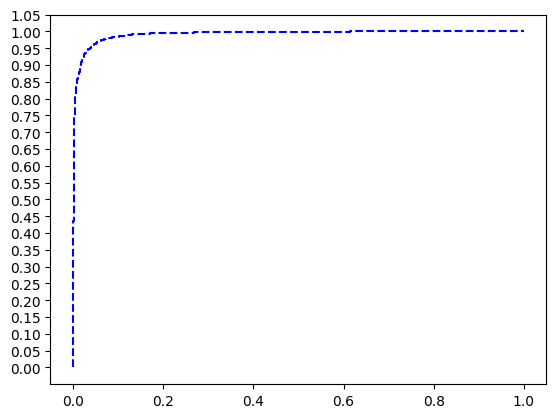

In [85]:
from matplotlib import pyplot as plt
plt.plot(fpr, tpr, linestyle='--', color='blue')
plt.yticks(np.arange(0, 1.1, step=0.05))

In [86]:
thresh

array([           inf, 9.99999225e-01, 9.99987960e-01, 9.99987066e-01,
       9.99976993e-01, 9.99975383e-01, 9.99959588e-01, 9.99958098e-01,
       9.99907792e-01, 9.99907613e-01, 9.99740064e-01, 9.99738753e-01,
       9.99695301e-01, 9.99692082e-01, 9.99143243e-01, 9.99142289e-01,
       9.99127388e-01, 9.99125421e-01, 9.98903155e-01, 9.98900712e-01,
       9.98556912e-01, 9.98556793e-01, 9.98237073e-01, 9.98235881e-01,
       9.96808350e-01, 9.96803880e-01, 9.96017218e-01, 9.96007323e-01,
       9.95914817e-01, 9.95912433e-01, 9.95354414e-01, 9.95352447e-01,
       9.95223939e-01, 9.95219409e-01, 9.93391097e-01, 9.93380904e-01,
       9.92625594e-01, 9.92618978e-01, 9.91563559e-01, 9.91556287e-01,
       9.91072059e-01, 9.91058588e-01, 9.88655210e-01, 9.88644361e-01,
       9.87608254e-01, 9.87602293e-01, 9.87579107e-01, 9.87536073e-01,
       9.78126466e-01, 9.78080332e-01, 9.61788952e-01, 9.61700499e-01,
       9.57057714e-01, 9.57017899e-01, 9.53714371e-01, 9.53704655e-01,
      

([<matplotlib.axis.YTick at 0x7f6f72e6acb0>,
 [Text(0, 0.0, '0.00'),
  Text(0, 0.05, '0.05'),
  Text(0, 0.1, '0.10'),
  Text(0, 0.15000000000000002, '0.15'),
  Text(0, 0.2, '0.20'),
  Text(0, 0.25, '0.25'),
  Text(0, 0.30000000000000004, '0.30'),
  Text(0, 0.35000000000000003, '0.35'),
  Text(0, 0.4, '0.40'),
  Text(0, 0.45, '0.45'),
  Text(0, 0.5, '0.50'),
  Text(0, 0.55, '0.55'),
  Text(0, 0.6000000000000001, '0.60'),
  Text(0, 0.65, '0.65'),
  Text(0, 0.7000000000000001, '0.70'),
  Text(0, 0.75, '0.75'),
  Text(0, 0.8, '0.80'),
  Text(0, 0.8500000000000001, '0.85'),
  Text(0, 0.9, '0.90'),
  Text(0, 0.9500000000000001, '0.95'),
  Text(0, 1.0, '1.00'),
  Text(0, 1.05, '1.05')])

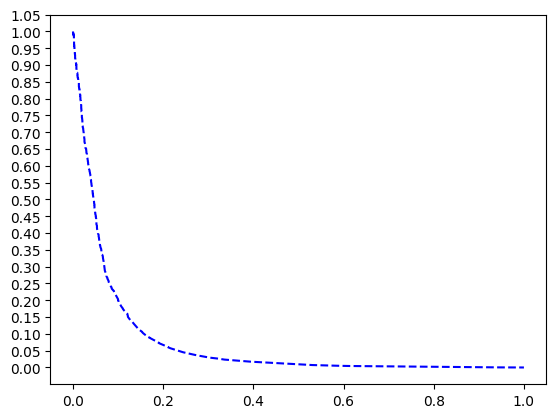

In [89]:
plt.plot(fpr, thresh, linestyle='--', color='blue')
plt.yticks(np.arange(0, 1.1, step=0.05))

In [90]:
tpr

array([0.00000000e+00, 3.04321363e-04, 1.82592818e-03, 2.43457091e-03,
       4.86914181e-03, 5.47778454e-03, 9.73828363e-03, 1.03469264e-02,
       2.09981741e-02, 2.16068168e-02, 5.26475959e-02, 5.32562386e-02,
       5.81253804e-02, 5.87340231e-02, 1.16250761e-01, 1.16859404e-01,
       1.18076689e-01, 1.18685332e-01, 1.41205113e-01, 1.41813755e-01,
       1.67376750e-01, 1.67985393e-01, 1.88374924e-01, 1.88983567e-01,
       2.58673159e-01, 2.59281802e-01, 2.92452830e-01, 2.92452830e-01,
       2.97321972e-01, 2.97930615e-01, 3.27145466e-01, 3.27754108e-01,
       3.32927572e-01, 3.32927572e-01, 3.91357273e-01, 3.91965916e-01,
       4.11138162e-01, 4.11138162e-01, 4.34570907e-01, 4.34570907e-01,
       4.43700548e-01, 4.44309191e-01, 4.87522824e-01, 4.87522824e-01,
       5.06695070e-01, 5.06695070e-01, 5.07608034e-01, 5.07608034e-01,
       6.09860012e-01, 6.09860012e-01, 7.02678028e-01, 7.02678028e-01,
       7.20328667e-01, 7.20328667e-01, 7.33110164e-01, 7.33718807e-01,
      